# ConnectaTel: Customer Usage Analysis and Segmentation

ConnectaTel is a telecommunications company operating in Latin America. Using 2024 data on 4,000 customers and 40,000 usage events (calls and texts), this analysis answers four business questions:

1. Which customer segments use calls and texts more or less?
2. Which customers show extreme usage that could signal unusual behaviour, fraud or capture errors?
3. How does usage vary by age and plan?
4. What should ConnectaTel change in its plans and retention strategy?

**Datasets**
- `plans.csv`: the two current plans (price, included minutes, texts and GB, overage costs)
- `users_latam.csv`: one row per customer (age, city, registration date, plan, churn date)
- `usage.csv`: one row per call or text (type, date, call duration, text length)

**Summary**
- Usage level, not age or plan, is the clearest signal of churn risk: the high-usage segment (7% of customers) has the lowest share of active customers.
- Age does not predict usage: the three age groups have almost identical usage mixes.
- 109 customers are extreme call-minute users. They look like genuine heavy users (possibly business accounts), not errors, and are a natural target for an unlimited or business plan.

The full executive summary is in [section 7](#7-executive-summary).

> Note: variable names and category labels are kept in Spanish, as in the source data. For example, `cant_mensajes` = number of texts, `cant_llamadas` = number of calls, `grupo_uso` = usage group (*Bajo / Medio / Alto uso* = low / medium / high usage), `grupo_edad` = age group (*Joven / Adulto / Adulto Mayor* = young / adult / senior).

---
## 1. Load and explore

### 1.1 Load the data

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load the three datasets
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
plans.head(5)  # first 5 rows of plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head(5)  # first 5 rows of users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head(5)  # first 5 rows of usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


### 1.2 Structure of each dataset

Rows, columns, data types and non-null counts, to spot problems before any analysis.

In [7]:
print('plans',plans.shape)
plans.info()  # columns, types and non-null counts

plans (2, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
print('users',users.shape)
users.info()  # columns, types and non-null counts

users (4000, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
print('usage',usage.shape)
usage.info()  # columns, types and non-null counts

usage (40000, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---
## 2. Data quality

### 2.1 Missing values

`plans` has only 2 rows and no missing values, so the checks focus on `users` and `usage`.

In [10]:
# Missing values in users: count and %
print('cantidad de nulos para users',users.isna().sum())
print('proporcion de nulos para users',users.isna().mean()*100)

cantidad de nulos para users user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
proporcion de nulos para users user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [11]:
# Missing values in usage: count and %
print(usage.isna().sum())
print(usage.isna().mean()*100)

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64


**Diagnosis**
- `city`: 469 missing (11.7%). City is a useful segmentation dimension, so I don't fill it with another city: that would invent data. These stay as missing and the rows are kept.
- `churn_date`: 88.4% missing. This is expected: an empty churn date means the customer is still active.
- `duration` (55.2%) and `length` (44.7%): too many to be random capture errors. I test why in step 3.2.
- `date` in `usage`: 50 missing (0.125%). Negligible, left as missing.

### 2.2 Invalid values and sentinels

Sentinels are placeholder values (like -999 or "?") that look valid to pandas but aren't real data.

In [12]:
columnas_numericas_users= users.select_dtypes(include='number')  # numeric columns in users
print(columnas_numericas_users.describe())  # age has a minimum of -999: a sentinel
users.duplicated().sum()  # no duplicate rows

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


0

In [13]:
columnas_numericas_usage= usage.select_dtypes(include = 'number')  # numeric columns in usage
print(columnas_numericas_usage.describe())  # duration and length have low counts; the id columns are complete
usage.duplicated().sum()  # no duplicate rows

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


0

In [14]:
users.select_dtypes(include='object').value_counts()  # categorical columns in users
columnas_user = ['city', 'plan']  # city uses "?" as a sentinel instead of NaN
print(users.select_dtypes(include='object').value_counts())  # reg_date and churn_date are stored as text
print(users[['city','plan']].value_counts())  # plan only contains Basico and Premium, no typos

first_name  last_name  city      reg_date                       plan     churn_date 
Ana         Garcia     ?         2023-07-27 00:09:43.345836464  Premium  1,73336E+18    1
Mariana     Ramirez    CDMX      2024-02-11 08:19:05.086271568  Basico   1,71841E+18    1
Mateo       Garcia     Bogotá    2022-01-13 01:09:08.237059264  Basico   1,7312E+18     1
Mariana     Torres     Medellín  2024-10-02 11:04:21.965491376  Premium  1,72238E+18    1
                       MTY       2024-03-22 14:20:58.514628664  Premium  1,72212E+18    1
                                                                                       ..
Carlos      Torres     CDMX      2023-01-02 15:25:47.486871720  Basico   1,72653E+18    1
                                 2022-09-23 21:03:54.958739688  Basico   1,7337E+18     1
                       Bogotá    2024-10-28 17:57:01.755438864  Premium  1,71876E+18    1
                                 2024-05-21 00:23:45.956489120  Basico   1,73007E+18    1
Sofia       Tor

In [15]:
print(usage.select_dtypes(include='object').value_counts())  # categorical column in usage
print(usage['type'].value_counts())  # type has two categories (text, call); date must be converted to datetime

type  date                         
call  2024-01-01 00:00:00.000000000    1
text  2024-03-13 08:52:59.599489987    1
      2024-03-13 07:28:16.992424810    1
      2024-03-13 07:54:20.871521788    1
      2024-03-13 08:00:51.841296032    1
                                      ..
call  2024-05-14 20:41:12.181804544    1
      2024-05-14 20:54:14.121353032    1
      2024-05-14 21:07:16.060901522    1
      2024-05-14 21:13:47.030675766    1
text  2024-06-29 23:53:29.030225754    1
Length: 39950, dtype: int64
text    22092
call    17908
Name: type, dtype: int64


**Diagnosis**
- `age` has a minimum of -999, an impossible value used as a sentinel. It is replaced with the median in step 3.1.
- `city` uses "?" instead of a real null. It is converted to missing so it is counted correctly.
- `reg_date`, `churn_date` and `date` are stored as text. They need to be datetimes to compare periods (MoM, YoY).
- `plan` only contains Basico and Premium, with no typos. Neither dataset has duplicate rows.

### 2.3 Dates

The data should only go up to 2024, so any later year is a capture error.

In [16]:
# Convert reg_date to datetime; unparseable values become NaT
users['reg_date'] = pd.to_datetime(users['reg_date'], errors = 'coerce')

In [17]:
# Convert date to datetime
usage['date'] = pd.to_datetime(usage['date'], errors = 'coerce')

In [18]:
# Years present in reg_date
users['reg_date'].dt.year.value_counts()

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

In [19]:
# Years present in usage date
usage['date'].dt.year.value_counts()
print(usage['date'].dtype)

print(usage['date'].dt.year.head(10))

print(usage['date'].dt.year.value_counts(dropna=False))
# only 2024 data is available

datetime64[ns]
0    2024.0
1    2024.0
2    2024.0
3    2024.0
4    2024.0
5    2024.0
6    2024.0
7    2024.0
8    2024.0
9    2024.0
Name: date, dtype: float64
2024.0    39950
NaN          50
Name: date, dtype: int64


In [20]:
# Records with impossible years (future or negative)
print(users[(users['reg_date'].dt.year>2024)|(users['reg_date'].dt.year<0)])
print(usage[(usage['date'].dt.year>2024)|(usage['date'].dt.year<0)])

      user_id first_name last_name  age      city   reg_date     plan  \
40      10040        Ana    Garcia   59  Medellín 2026-05-10   Basico   
56      10056       Luis    Garcia   29      CDMX 2026-05-10   Basico   
60      10060     Carlos    Torres   45      CDMX 2026-05-10   Basico   
70      10070    Mariana     Gomez   50      CDMX 2026-05-10  Premium   
248     10248      Sofia    Garcia   20  Medellín 2026-05-10  Premium   
320     10320      Sofia    Garcia   74       GDL 2026-05-10  Premium   
326     10326    Mariana    Torres   51  Medellín 2026-05-10  Premium   
505     10505       Luis    Garcia   75      CDMX 2026-05-10   Basico   
527     10527     Carlos    Torres   71       MTY 2026-05-10   Basico   
646     10646       Luis   Ramirez   50      CDMX 2026-05-10  Premium   
885     10885        Ana    Torres   73    Bogotá 2026-05-10   Basico   
914     10914    Mariana    Garcia   25       GDL 2026-05-10   Basico   
948     10948      Sofia    Torres   30       MTY 2

**Diagnosis**
- `reg_date`: 40 customers (1.0%) have an impossible registration date in the future (2026-05-10). I set these dates to missing instead of deleting the rows, so the rest of each customer's data is kept. No negative years.
- `date` in `usage`: every valid date is in 2024. The 50 missing values make pandas display the year as a float (2024.0), which does not affect the analysis.

---
## 3. Cleaning

### 3.1 Fix sentinels and impossible dates

- `age`: replace -999 with the median (47). The median is not pulled by the sentinel the way the mean is.
- `city`: replace "?" with a real missing value.
- `reg_date`: set future dates to missing.

In [21]:
# Replace the -999 sentinel with the median age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Check
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [22]:
# Replace the "?" sentinel with a real missing value
users['city']= users['city'].replace('?',pd.NA)

# Check
users['city'].value_counts()

Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [23]:
# Set future registration dates to missing
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT
# Check
users['reg_date'].value_counts()

2024-06-27 06:08:22.325581392    1
2023-03-31 06:21:20.120030008    1
2024-06-20 09:50:54.463615904    1
2022-05-22 00:23:45.956489122    1
2022-04-23 06:22:24.936234060    1
                                ..
2022-07-29 04:44:06.661665416    1
2022-02-22 00:36:43.750937734    1
2022-10-31 09:22:49.242310580    1
2022-09-24 16:46:48.702175544    1
2022-03-28 12:38:20.975243811    1
Name: reg_date, Length: 3960, dtype: int64

### 3.2 Are the missing `duration` and `length` values MAR?

Hypothesis: if the missing values depend on `type` (call vs text), they are structural, not errors.

In [24]:
usage['duration_nulos']=usage['duration'].isna()
usage.groupby('type')['duration_nulos'].sum()  # MAR check: are missing durations concentrated in one type?

type
call        0
text    22076
Name: duration_nulos, dtype: int64

In [25]:
usage['length_nulos'] = usage['length'].isna()
usage.groupby('type')['length_nulos'].sum()  # MAR check: are missing lengths concentrated in one type?

type
call    17896
text        0
Name: length_nulos, dtype: int64

**Diagnosis: MAR.** All 22,076 missing durations are texts, and all 17,896 missing lengths are calls. Texts are measured by length and calls by duration, so each column is empty exactly where it doesn't apply. They stay as missing: imputing them would create fake call durations for texts.

---
## 4. Usage metrics per customer

### 4.1 Aggregate usage by customer

One row per customer with:
- `cant_mensajes`: total texts
- `cant_llamadas`: total calls
- `cant_minutos_llamada`: total call minutes

Then join it with the customer table to build `user_profile`, the base for the rest of the analysis.

In [26]:
# Helper columns to count texts and calls
usage["is_text"] = (usage["type"] == "text").astype(int)
usage["is_call"] = (usage["type"] == "call").astype(int)


# Aggregate usage per customer
usage_agg = usage.groupby('user_id').agg({'is_text':'sum','is_call':'sum', 'duration':'sum'}).reset_index()

# Check result
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Rename columns
usage_agg.rename(columns={'is_text':'cant_mensajes', 'is_call':'cant_llamadas', 'duration':'cant_minutos_llamada'}, inplace= True)
# Check result
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [28]:
# Join aggregated usage with customer data
user_profile = usage_agg.merge(users,on='user_id', how= 'inner')
user_profile.head(5)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,5,10,33.18,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


### 4.2 Summary statistics (2024)

In [29]:
user_profile.select_dtypes(include='number').describe()  # summary statistics for numeric columns

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,age
count,3999.000000,3999.000000,3999.000000,3999.000000,3999.000000
mean,11999.729432,5.524381,4.478120,23.317054,48.124531
std,1154.898108,2.358416,2.144238,18.168095,17.692032
min,10000.000000,0.000000,0.000000,0.000000,18.000000
25%,10999.500000,4.000000,3.000000,11.120000,33.000000
50%,12000.000000,5.000000,4.000000,19.780000,47.000000
75%,12999.500000,7.000000,6.000000,31.415000,63.000000
max,13999.000000,17.000000,15.000000,155.690000,79.000000


In [30]:
user_profile['plan'].value_counts(normalize=True)*100  # plan distribution (%)

Basico     64.866217
Premium    35.133783
Name: plan, dtype: float64

---
## 5. Distributions and outliers

### 5.1 Distributions by plan

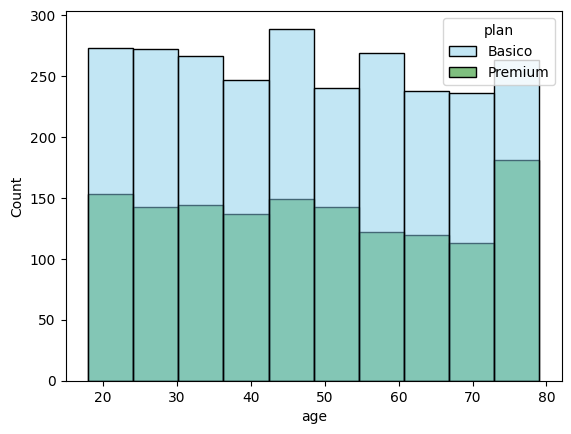

In [31]:
# Age distribution by plan
sns.histplot(data=user_profile, x='age',bins = 10, hue= 'plan', palette=['skyblue','green'], edgecolor = 'black')
plt.show()

**Insight:** age has peaks around 20, 50 and 80. Premium is over-represented in those peaks, most clearly among customers around 80, where roughly 70% are on Premium.

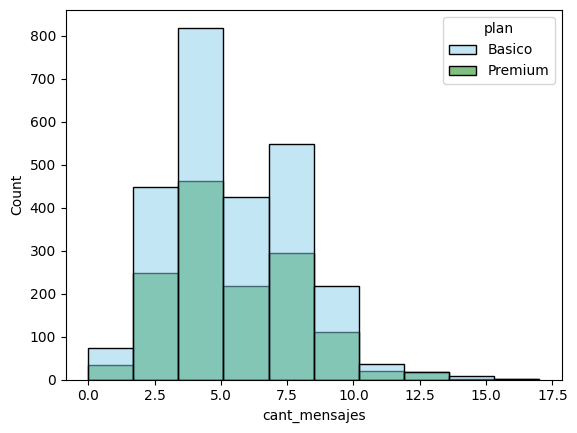

In [32]:
# Texts per customer by plan
sns.histplot(data=user_profile, x='cant_mensajes', bins= 10, hue= 'plan', palette=['skyblue','green'], edgecolor='black')
plt.show()

**Insight:** texts per customer are right-skewed. Most customers send 3 to 5 texts, with a tail reaching 17. Customers with 11 or more texts are mostly or entirely on Premium.

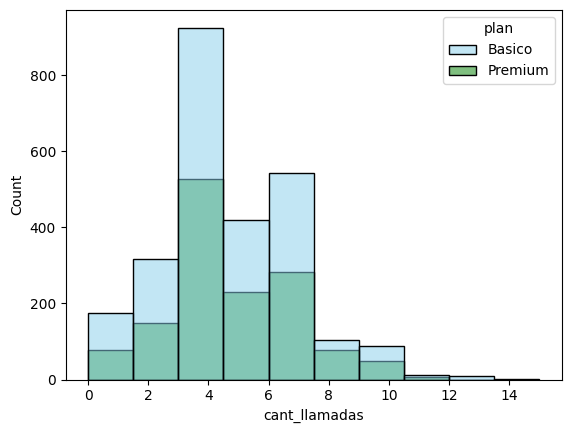

In [33]:
# Calls per customer by plan
sns.histplot(data=user_profile, x='cant_llamadas', bins= 10, hue='plan', palette=['skyblue', 'green'], edgecolor='black')
plt.show()

**Insight:** calls per customer are right-skewed, with most customers making 3 to 4 calls and a thin tail up to 14. Unlike texts, Basico and Premium are spread proportionally across most of the range.

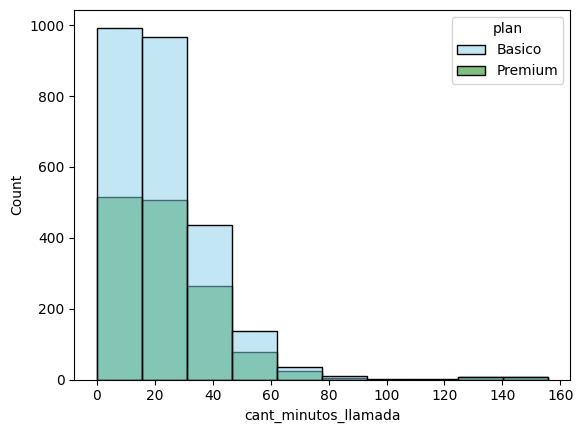

In [34]:
# Call minutes per customer by plan
sns.histplot(data=user_profile, x='cant_minutos_llamada', bins= 10, hue='plan', palette= ['skyblue','green'], edgecolor= 'black')
plt.show()

**Insight:** call minutes are strongly right-skewed: most customers talk 0 to 30 minutes, with a long tail up to 160. This is the clearest plan pattern: **the more minutes a customer uses, the higher the share of Premium.**

### 5.2 Outliers

Boxplots to spot extreme values, then the IQR method to quantify them and decide whether to keep them.

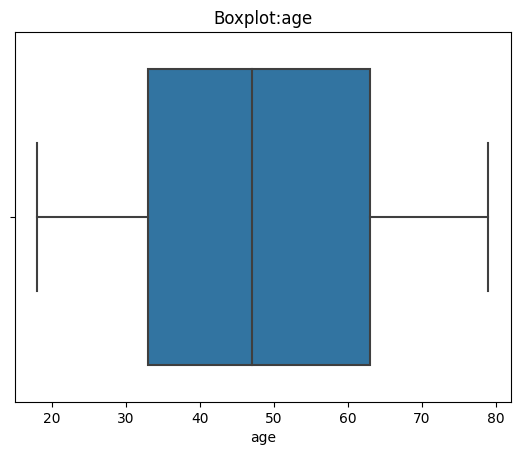

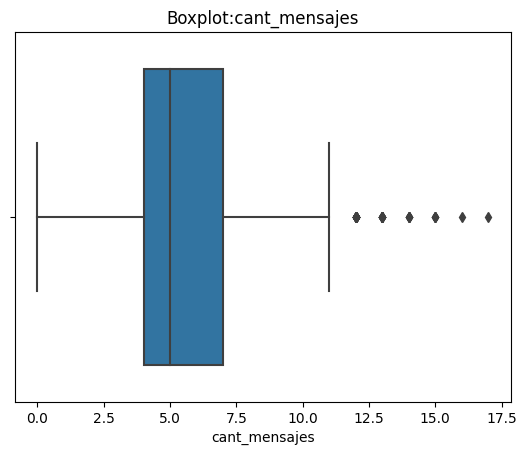

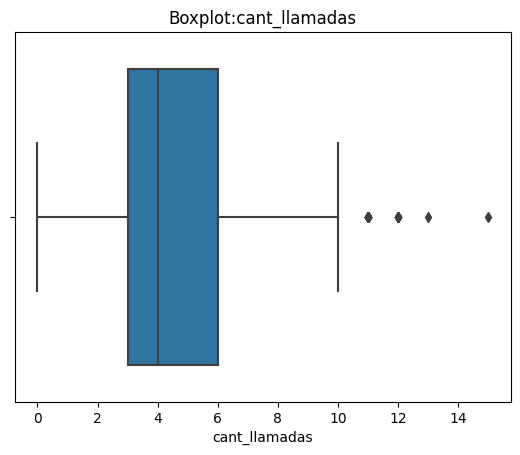

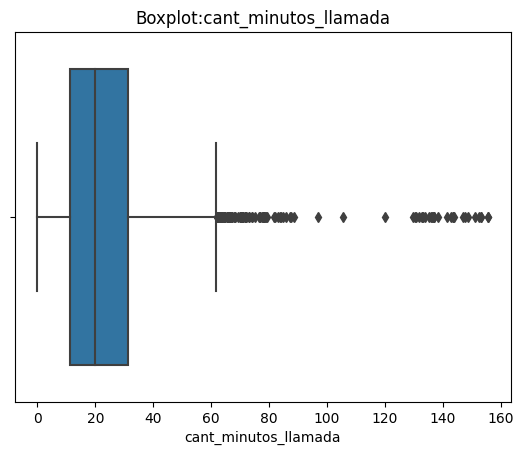

In [35]:
# Boxplots to spot outliers
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot:{col}')
    plt.show()

**What the boxplots show**
- `age`: no outliers. All values sit within the whiskers.
- `cant_mensajes`: outliers on the right, between 12 and 17 texts. The middle 50% sends 3 to 5.
- `cant_llamadas`: outliers on the right, between 11 and 15 calls. The middle 50% makes 3 to 6.
- `cant_minutos_llamada`: many outliers, from 62 to 160 minutes. The middle 50% talks 12 to 35 minutes. This is the most extreme variable of the four.

In [36]:
# IQR limits and % of outliers per column
columnas_limites = ['cant_mensajes','cant_llamadas','cant_minutos_llamada']
for col in columnas_limites:
    Q1= user_profile[col].quantile(0.25)
    Q3= user_profile[col].quantile(0.75)
    IQR= Q3-Q1
    upper= Q3 + 1.5*IQR
    lower= Q1 -1.5*IQR
    print(f'{col}: lower:{lower}, upper:{upper}')
    outliers= user_profile[user_profile[col]> upper]
    print(outliers.shape[0])
    porcentaje = (outliers.shape[0] / len(user_profile)) * 100
    print(f'{col}: {porcentaje:.2f}% de outliers')

cant_mensajes: lower:-0.5, upper:11.5
46
cant_mensajes: 1.15% de outliers
cant_llamadas: lower:-1.5, upper:10.5
30
cant_llamadas: 0.75% de outliers
cant_minutos_llamada: lower:-19.322500000000005, upper:61.8575
109
cant_minutos_llamada: 2.73% de outliers


In [37]:
# Compare upper limits with the max to decide whether to keep outliers
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


**Decision: keep all outliers.** None of them look like capture errors.
- `cant_mensajes`: 46 customers (1.15%) with 12 to 17 texts. Realistic for people who use texting as their main channel.
- `cant_llamadas`: 30 customers (0.75%) with 11 to 15 calls. Realistic heavy users.
- `cant_minutos_llamada`: 109 customers (2.73%) with 62 to 160 minutes, the largest group. Plausibly business or high-consumption profiles.

Removing them would delete exactly the heavy-usage segment the business questions ask about.

---
## 6. Customer segmentation

### 6.1 By usage

- *Bajo uso* (low): fewer than 5 calls and fewer than 5 texts
- *Uso medio* (medium): fewer than 10 calls and fewer than 10 texts
- *Alto uso* (high): everyone else

In [38]:
# Create usage group

def clasificar_uso(row):
    if row['cant_mensajes'] < 5 and row['cant_llamadas'] < 5:
        return 'Bajo uso'
    elif row['cant_mensajes'] < 10 and row['cant_llamadas']< 10:
        return 'Uso medio'
    else:
        return 'Alto uso'
user_profile['grupo_uso'] =user_profile.apply(clasificar_uso, axis=1)

In [45]:
# Check
user_profile['grupo_uso'].value_counts()

Uso medio    2943
Bajo uso      778
Alto uso      278
Name: grupo_uso, dtype: int64

### 6.2 By age

- *Joven* (young): under 30
- *Adulto* (adult): 30 to 59
- *Adulto Mayor* (senior): 60 and over

In [40]:
# Create age group
def clasificar_edad(row):
    if row['age'] < 30:
        return 'Joven'
    elif row['age'] < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'
user_profile['grupo_edad'] =user_profile.apply(clasificar_edad, axis=1)

In [44]:
# Check
user_profile['grupo_edad'].value_counts()

Adulto          2017
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

### 6.3 Segment sizes

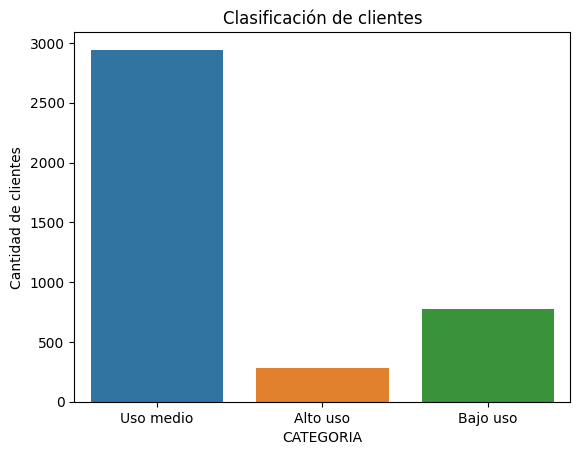

In [42]:
# Segment sizes by usage
sns.countplot(data=user_profile, x='grupo_uso')
plt.title('Clasificación de clientes')
plt.xlabel('CATEGORIA')
plt.ylabel('Cantidad de clientes')
plt.show()

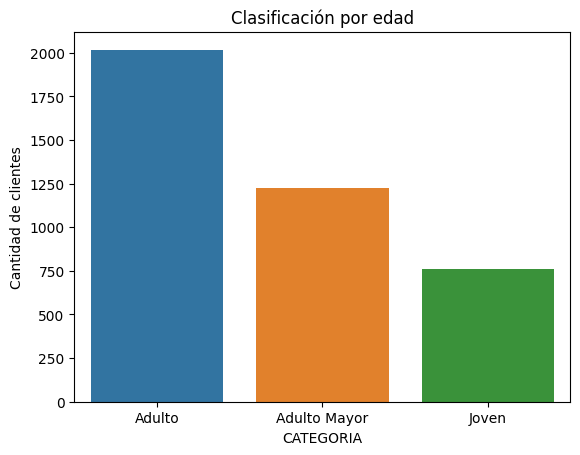

In [43]:
# Segment sizes by age
sns.countplot(data=user_profile, x='grupo_edad')
plt.title('Clasificación por edad')
plt.xlabel('CATEGORIA')
plt.ylabel('Cantidad de clientes')
plt.show()

### 6.4 Cross-segment checks

Three questions before drawing conclusions: does usage depend on age, is high usage concentrated in Premium, and which segment churns most?

In [46]:
# Usage mix within each age group (%)
pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize='index') * 100

grupo_uso,Alto uso,Bajo uso,Uso medio
grupo_edad,,,
Adulto,7.585523,18.046604,74.367873
Adulto Mayor,6.055646,21.031097,72.913257
Joven,6.710526,20.657895,72.631579


In [47]:
# Is high usage concentrated in Premium?
pd.crosstab(user_profile['grupo_uso'], user_profile['plan'], normalize='index') * 100

plan,Basico,Premium
grupo_uso,,
Alto uso,66.546763,33.453237
Bajo uso,65.809769,34.190231
Uso medio,64.458036,35.541964


In [48]:
# % of each usage segment still active (no churn date)
user_profile['activo'] = user_profile['churn_date'].isna()
user_profile.groupby('grupo_uso')['activo'].mean() * 100

grupo_uso
Alto uso     85.971223
Bajo uso     88.560411
Uso medio    88.515121
Name: activo, dtype: float64

In [49]:
# Retention and Premium share among call-minute outliers
Q1 = user_profile['cant_minutos_llamada'].quantile(0.25)
Q3 = user_profile['cant_minutos_llamada'].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5*IQR

outliers_users = user_profile[user_profile['cant_minutos_llamada'] > upper]

print('% activos entre outliers:', outliers_users['activo'].mean()*100)
print('% Premium entre outliers:', (outliers_users['plan']=='Premium').mean()*100)

% activos entre outliers: 87.1559633027523
% Premium entre outliers: 39.44954128440367


---
## 7. Executive summary

**Data issues found and how they were handled**
- `duration` and `length` were 55.2% and 44.7% missing. This was confirmed as MAR (each column only applies to one event type), so they were left as missing.
- `age` had a -999 sentinel (replaced with the median), `city` had a "?" sentinel (469 customers, 11.7%), and `reg_date` had 40 impossible future dates (2026), set to missing.

**Age segments**
- Adult 50.4%, Senior 30.6%, Young 19.0%.
- The three age groups have almost identical low / medium / high usage mixes. **Age does not predict usage.**

**Usage segments**
- Medium 73.6%, Low 19.5%, High 7.0%.
- The high-usage segment has the lowest share of active customers (86.0% vs 88.5% in the other two) and is not more Premium than the rest (33% vs about 35%).
- The 109 call-minute outliers are 87.2% active and 39.4% Premium (vs 35.1% overall): heavy users who already lean toward the higher plan.

**Conclusion:** usage level, not age or plan, is the clearest signal of churn risk. The heaviest users are also the most likely to leave, which makes them a high-impact retention target despite their small size.

> Caveat: the retention gap is small (about 2.5 points) and the high-usage segment has only 278 customers, so it should be validated with more data or a significance test before committing budget.

**Recommendations**
1. Run a proactive retention program for the high-usage segment: priority support or targeted offers before they churn.
2. Design an unlimited or business plan for the ~109 heavy call-minute users, whose consumption is far above the rest.
3. Don't segment offers by age. Segment by actual usage behaviour.